# Outcome vs Uncertainty — 1 BTG

Plots:
1. T1 BCAS death rate vs selected uncertainty
2. Fraction of T2 treated within NATO timeline vs selected uncertainty

In [31]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260603_153636_scenario_1ccp_1btg_egalitarian"
UNCERTAINTY = "wave_duration_min"   # <-- change this to any uncertainty column
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
levels = sorted(df[UNCERTAINTY].unique())
print(f"Loaded {len(df)} runs  |  {UNCERTAINTY} levels: {levels}")

Loaded 800 runs  |  wave_duration_min levels: [np.int64(1), np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(120)]


In [32]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec

def median_ci(vals, n_boot=1000, alpha=0.05):
    """Bootstrap 95% CI half-width for the median."""
    if len(vals) < 2:
        return np.nan
    rng = np.random.default_rng(42)
    boots = np.array([np.median(rng.choice(vals, size=len(vals))) for _ in range(n_boot)])
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return (hi - lo) / 2

def plot_diagnostic_matrix(rows, triage_label):
    """
    Heatmap with dual colour scales.
    Each row is (label, column_name) or (label, column_name, agg)
    where agg is 'median' (default), 'q25', or 'q75'.
    Rows whose label starts with 'Mortality' use Reds; all others use Blues.
    """
    # normalise rows to 3-tuples
    rows_norm = [(r[0], r[1], r[2] if len(r) > 2 else "median") for r in rows]

    matrix = pd.DataFrame(index=[r[0] for r in rows_norm], columns=[str(lv) for lv in levels], dtype=float)
    ci_mat = pd.DataFrame(index=[r[0] for r in rows_norm], columns=[str(lv) for lv in levels], dtype=float)

    for label, col, agg in rows_norm:
        for lv in levels:
            vals = df.loc[df[UNCERTAINTY] == lv, col].dropna().values
            if len(vals) == 0:
                matrix.loc[label, str(lv)] = np.nan
                ci_mat.loc[label, str(lv)] = np.nan
                continue
            if agg == "q25":
                matrix.loc[label, str(lv)] = np.percentile(vals, 25)
            elif agg == "q75":
                matrix.loc[label, str(lv)] = np.percentile(vals, 75)
            else:
                matrix.loc[label, str(lv)] = np.median(vals)
            ci_mat.loc[label, str(lv)] = median_ci(vals)

    mort_idx = [i for i, (lab, _, __) in enumerate(rows_norm) if lab.startswith("Mortality")]
    wait_idx = [i for i in range(len(rows_norm)) if i not in mort_idx]

    vals_f = matrix.values.astype(float)
    wait_vals = vals_f[wait_idx, :].flatten()
    mort_vals = vals_f[mort_idx, :].flatten()
    norm_wait = Normalize(vmin=np.nanmin(wait_vals), vmax=np.nanmax(wait_vals))
    norm_mort = Normalize(vmin=np.nanmin(mort_vals), vmax=np.nanmax(mort_vals))
    cmap_wait = plt.cm.Blues
    cmap_mort = plt.cm.Reds

    n_rows, n_cols = vals_f.shape

    fig = plt.figure(figsize=(max(9, n_cols * 1.5 + 2), n_rows * 0.85 + 1.5))
    gs = gridspec.GridSpec(2, 2, width_ratios=[1, 0.03], height_ratios=[1, 1],
                           wspace=0.05, hspace=0.08)
    ax = fig.add_subplot(gs[:, 0])
    cax_w = fig.add_subplot(gs[0, 1])
    cax_m = fig.add_subplot(gs[1, 1])

    for i in range(n_rows):
        is_mort = i in mort_idx
        norm = norm_mort if is_mort else norm_wait
        cmap = cmap_mort if is_mort else cmap_wait
        for j in range(n_cols):
            v = vals_f[i, j]
            color = cmap(norm(v)) if not np.isnan(v) else (0.95, 0.95, 0.95, 1)
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, facecolor=color, edgecolor="white", lw=1.5))
            if not np.isnan(v):
                ci = ci_mat.iloc[i, j]
                txt = f"{v:.3f}\n(±{ci:.3f})" if not np.isnan(ci) else f"{v:.3f}"
                brightness = 0.299 * color[0] + 0.587 * color[1] + 0.114 * color[2]
                ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                        color="white" if brightness < 0.55 else "black")

    ax.set_xlim(-0.5, n_cols - 0.5)
    ax.set_ylim(n_rows - 0.5, -0.5)
    ax.set_xticks(range(n_cols))
    ax.set_xticklabels([str(lv) for lv in levels])
    ax.set_yticks(range(n_rows))
    ax.set_yticklabels([r[0] for r in rows_norm])
    ax.set_xlabel(UNCERTAINTY)
    ax.set_title(f"{triage_label} Diagnostic Matrix — per {UNCERTAINTY} level")

    fig.colorbar(ScalarMappable(norm=norm_wait, cmap=cmap_wait), cax=cax_w, label="Wait (min)")
    fig.colorbar(ScalarMappable(norm=norm_mort, cmap=cmap_mort), cax=cax_m, label="Mortality rate")

    plt.tight_layout()
    plt.show()
    print(matrix.to_string(float_format="%.4f"))
    return matrix

def boxplot_by_uncertainty(outcome, ylabel, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 5))
    data = [df.loc[df[UNCERTAINTY] == lv, outcome].dropna().values for lv in levels]
    bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)
    for patch in bp["boxes"]:
        patch.set_facecolor("steelblue")
        patch.set_alpha(0.7)
    for i, d in enumerate(data):
        if len(d) > 0:
            med = np.median(d)
            ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")
    ax.set_xlabel(UNCERTAINTY)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    return ax

## 1. T1 BCAS Death Rate

C:\Users\User\AppData\Local\Temp\ipykernel_15736\2435043612.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


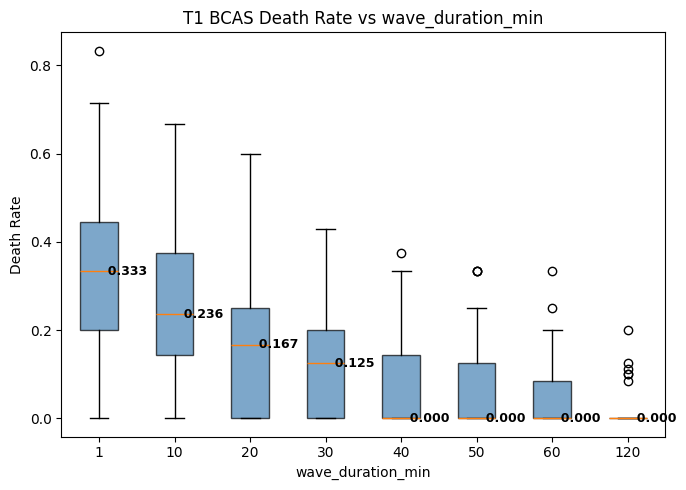

                    mean  median    std    min    max
wave_duration_min                                    
1                 0.3307  0.3333 0.1943 0.0000 0.8333
10                0.2488  0.2361 0.1710 0.0000 0.6667
20                0.1707  0.1667 0.1476 0.0000 0.6000
30                0.1164  0.1250 0.1186 0.0000 0.4286
40                0.0744  0.0000 0.0983 0.0000 0.3750
50                0.0622  0.0000 0.0927 0.0000 0.3333
60                0.0380  0.0000 0.0690 0.0000 0.3333
120               0.0072  0.0000 0.0301 0.0000 0.2000


In [33]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_uncertainty("death_rate_T1_BCAS", "Death Rate", f"T1 BCAS Death Rate vs {UNCERTAINTY}", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby(UNCERTAINTY)["death_rate_T1_BCAS"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 2. Fraction of T2 Within NATO Timeline

C:\Users\User\AppData\Local\Temp\ipykernel_15736\2435043612.py:98: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


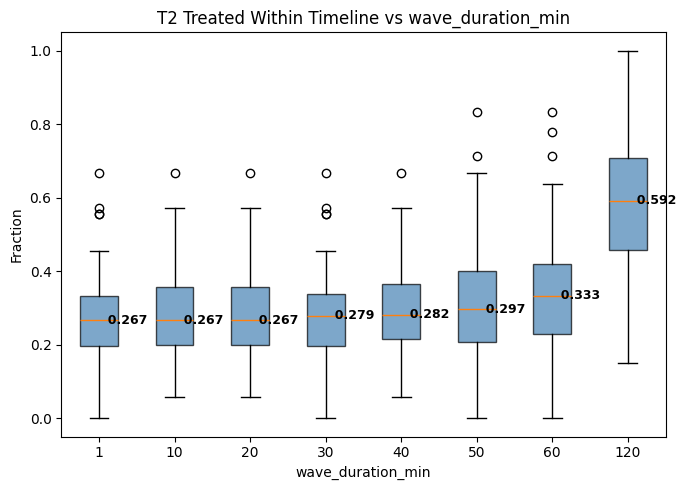

                    mean  median    std    min    max
wave_duration_min                                    
1                 0.2743  0.2667 0.1179 0.0000 0.6667
10                0.2802  0.2667 0.1210 0.0588 0.6667
20                0.2783  0.2667 0.1183 0.0588 0.6667
30                0.2776  0.2789 0.1179 0.0000 0.6667
40                0.2943  0.2817 0.1186 0.0588 0.6667
50                0.3061  0.2971 0.1430 0.0000 0.8333
60                0.3346  0.3333 0.1564 0.0000 0.8333
120               0.5851  0.5917 0.1766 0.1500 1.0000


In [34]:
fig, ax = plt.subplots(figsize=(7, 5))
boxplot_by_uncertainty("frac_t2_within_timeline", "Fraction", f"T2 Treated Within Timeline vs {UNCERTAINTY}", ax=ax)
plt.tight_layout()
plt.show()

print(df.groupby(UNCERTAINTY)["frac_t2_within_timeline"].agg(["mean", "median", "std", "min", "max"]).to_string(float_format="%.4f"))

## 3. Diagnostic Matrix — T1

C:\Users\User\AppData\Local\Temp\ipykernel_15736\2435043612.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


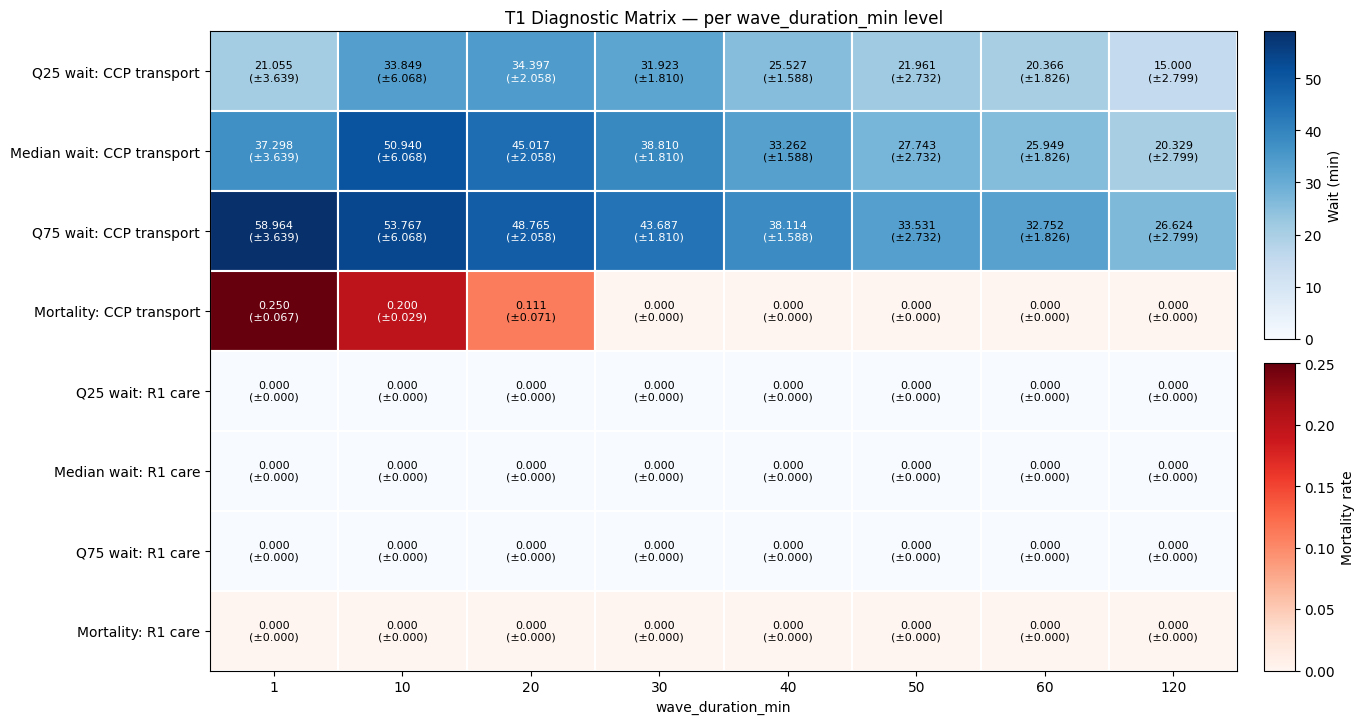

                                 1      10      20      30      40      50      60     120
Q25 wait: CCP transport    21.0552 33.8485 34.3965 31.9230 25.5274 21.9612 20.3664 15.0000
Median wait: CCP transport 37.2977 50.9399 45.0174 38.8104 33.2623 27.7434 25.9491 20.3294
Q75 wait: CCP transport    58.9642 53.7671 48.7654 43.6869 38.1139 33.5308 32.7517 26.6238
Mortality: CCP transport    0.2500  0.2000  0.1111  0.0000  0.0000  0.0000  0.0000  0.0000
Q25 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Median wait: R1 care        0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Q75 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Mortality: R1 care          0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000


,1,10,20,30,40,50,60,120
Q25 wait: CCP transport,21.055212,33.848521,34.396512,31.923028,25.527352,21.961214,20.366353,15.000000
Median wait: CCP transport,37.297682,50.939915,45.017354,38.810380,33.262305,27.743391,25.949080,20.329397
Q75 wait: CCP transport,58.964150,53.767126,48.765405,43.686870,38.113936,33.530774,32.751736,26.623823
Mortality: CCP transport,0.250000,0.200000,0.111111,0.000000,0.000000,0.000000,0.000000,0.000000
Q25 wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Median wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Q75 wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Mortality: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [35]:
t1_rows = [
    ("Q25 wait: CCP transport",     "median_wait_ccp_transport_T1", "q25"),
    ("Median wait: CCP transport",  "median_wait_ccp_transport_T1"),
    ("Q75 wait: CCP transport",     "median_wait_ccp_transport_T1", "q75"),
    ("Mortality: CCP transport",    "mortality_ccp_transport_T1"),
    ("Q25 wait: R1 care",           "median_wait_r1_care_T1", "q25"),
    ("Median wait: R1 care",        "median_wait_r1_care_T1"),
    ("Q75 wait: R1 care",           "median_wait_r1_care_T1", "q75"),
    ("Mortality: R1 care",          "mortality_r1_care_T1"),
    # ("Q25 wait: R1 transport",      "median_wait_r1_transport_T1", "q25"),
    # ("Median wait: R1 transport",   "median_wait_r1_transport_T1"),
    # ("Q75 wait: R1 transport",      "median_wait_r1_transport_T1", "q75"),
    # ("Mortality: R1 transport",     "mortality_r1_transport_T1"),
    # ("Q25 wait: R2 care",           "median_wait_r2_care_T1", "q25"),
    # ("Median wait: R2 care",        "median_wait_r2_care_T1"),
    # ("Q75 wait: R2 care",           "median_wait_r2_care_T1", "q75"),
    # ("Mortality: R2 care",          "mortality_r2_care_T1"),
]

plot_diagnostic_matrix(t1_rows, "T1")

## 4. Diagnostic Matrix — T2

C:\Users\User\AppData\Local\Temp\ipykernel_15736\2435043612.py:89: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


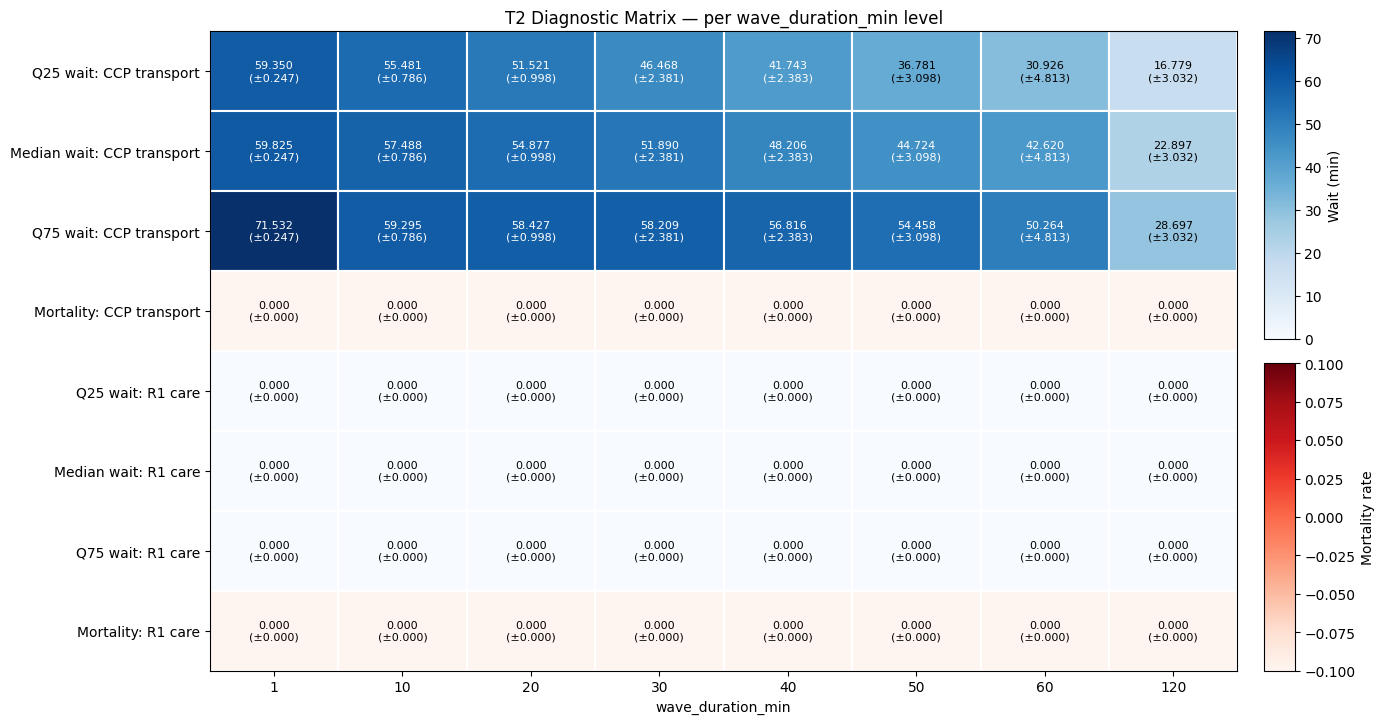

                                 1      10      20      30      40      50      60     120
Q25 wait: CCP transport    59.3499 55.4815 51.5208 46.4684 41.7433 36.7812 30.9259 16.7789
Median wait: CCP transport 59.8247 57.4882 54.8771 51.8905 48.2061 44.7244 42.6200 22.8968
Q75 wait: CCP transport    71.5316 59.2954 58.4265 58.2093 56.8158 54.4578 50.2644 28.6968
Mortality: CCP transport    0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Q25 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Median wait: R1 care        0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Q75 wait: R1 care           0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000
Mortality: R1 care          0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000


,1,10,20,30,40,50,60,120
Q25 wait: CCP transport,59.349891,55.481469,51.520760,46.468398,41.743335,36.781188,30.925900,16.778881
Median wait: CCP transport,59.824712,57.488157,54.877110,51.890498,48.206147,44.724407,42.620009,22.896755
Q75 wait: CCP transport,71.531590,59.295406,58.426516,58.209290,56.815800,54.457779,50.264383,28.696761
Mortality: CCP transport,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Q25 wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Median wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Q75 wait: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Mortality: R1 care,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [36]:
t2_rows = [
    ("Q25 wait: CCP transport",     "median_wait_ccp_transport_T2", "q25"),
    ("Median wait: CCP transport",  "median_wait_ccp_transport_T2"),
    ("Q75 wait: CCP transport",     "median_wait_ccp_transport_T2", "q75"),
    ("Mortality: CCP transport",    "mortality_ccp_transport_T2"),
    ("Q25 wait: R1 care",           "median_wait_r1_care_T2", "q25"),
    ("Median wait: R1 care",        "median_wait_r1_care_T2"),
    ("Q75 wait: R1 care",           "median_wait_r1_care_T2", "q75"),
    ("Mortality: R1 care",          "mortality_r1_care_T2"),
    # ("Q25 wait: R1 transport",      "median_wait_r1_transport_T2", "q25"),
    # ("Median wait: R1 transport",   "median_wait_r1_transport_T2"),
    # ("Q75 wait: R1 transport",      "median_wait_r1_transport_T2", "q75"),
    # ("Mortality: R1 transport",     "mortality_r1_transport_T2"),
    # ("Q25 wait: R2 care",           "median_wait_r2_care_T2", "q25"),
    # ("Median wait: R2 care",        "median_wait_r2_care_T2"),
    # ("Q75 wait: R2 care",           "median_wait_r2_care_T2", "q75"),
    # ("Mortality: R2 care",          "mortality_r2_care_T2"),
]

plot_diagnostic_matrix(t2_rows, "T2")